# Gate 5C: Regularized hierarchical Matryoshka Attribution

Test shared component scores plus centered edge residuals on pinned official GPT-2 Small IOI. All 32,491 edges remain eligible. GPT-2 weights never enter Adam; their complete hashes must remain unchanged. Official gradient flags, top-k differentiation, uniform-k sampling, live edge patching and CPR/CMD evaluator are preserved. No ranking refinement, expander, interaction training or leaderboard submission.

In [1]:
from pathlib import Path
import json, os, subprocess, re
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/mattr_hierarchy').is_dir())
CAMPAIGN_REL = 'results/mattr_hierarchy/20261022_gate5c'
OUT = ROOT / CAMPAIGN_REL
RUN_TESTS = False
RUN_PREPARE = False
RUN_REGISTERED_CAMPAIGN = False
REGENERATE_REPORT = False
print(OUT)


H:\GenAI Research\sketch_prune\results\mattr_hierarchy\20261022_gate5c


## Explicit execution controls

Default execution reads saved artifacts only. The pinned WSL environment is reused. Preparation freezes the training-only magnitude-check rule; the complete protocol and any scale replacement are then frozen before modified CPR is evaluated. The registered campaign stops automatically when a gate fails and never expands gamma values. Gamma-zero hierarchy is not ordinary MAttr; the dedicated bypass is the baseline-equivalence control.

In [2]:
def run(*args):
    script = ROOT / 'src/mattr_hierarchy/run_wsl.sh'
    if os.name == 'nt':
        path = '/mnt/' + script.drive[0].lower() + str(script)[2:].replace('\\', '/')
        command = ['wsl', '-d', 'Ubuntu', '--', 'bash', path, *args]
    else:
        command = ['bash', str(script), *args]
    subprocess.run(command, cwd=ROOT, check=True)
if RUN_TESTS: run('tests')
if RUN_PREPARE: run('--out', CAMPAIGN_REL, '--prepare-only')
if RUN_REGISTERED_CAMPAIGN: run('--out', CAMPAIGN_REL)
if REGENERATE_REPORT:
    run('--out', CAMPAIGN_REL, '--report-only')
    run('diagnostics', '--out', CAMPAIGN_REL)
    run('audit', '--out', CAMPAIGN_REL)


## Mappings, objective and scale convention

H1: each source head, MLP output and the official input source. H2: separate Q/K/V receivers per head, MLP receivers and logits. The disjoint maps preserve canonical edge ordering. `effective = h[group] + r - group_mean(r)`; penalty is `gamma * frozen_scale * mean(centered_r**2)`, with no h penalty. The shuffled control uses fixed seed 5701 and the exact same group sizes. A training-only probe at frozen ordinary 500-step scores checks the proposed gamma values before screening.

In [3]:
protocol = json.loads((OUT / 'gate5c_protocol.json').read_text())
print('Protocol SHA-256:', (OUT / 'gate5c_protocol.sha256').read_text().strip())
display(json.loads((OUT / 'mapping_audit.json').read_text()))
display(pd.read_csv(OUT / 'group_sizes.csv').groupby(['hierarchy', 'type']).edges.agg(['count', 'min', 'max', 'sum']))
display(protocol['regularization_scale'])
display(pd.read_csv(OUT / 'pilot/magnitude_probe.csv').groupby(['family', 'gamma'])[['mattr_abs_loss', 'penalty', 'gradient_ratio', 'loss_ratio']].median())
display(protocol['phaseB'])
display(protocol['phaseC'])


Protocol SHA-256: 3b85dbcc9a01c8e8892795bc3aa622895d4084885f239c6c351e9b8b4d36692e


{'passed': True,
 'canonical_mapping_sha256': 'c6fd1f0eecbcdfb89e42b1817cc9822ec4230e5adb22172dac7f5eac03a96dbe',
 'hierarchies': {'H1': {'edges': 32491,
   'groups': 157,
   'smallest': 1,
   'largest': 445,
   'singletons': 1,
   'ids_sha256': '38d1b82fc47d0b0b4f2cb0b682da635b3d04abf176a5e487b2b3af4518a3f32e',
   'shuffled_sha256': 'f6fdb7224f1a429595c52c3e4ed10746c3e6fec2b4f6d0e0efaad86d2d992f27',
   'shuffle_seed': 5701,
   'fallback': 'H1 input and H2 logits are explicit official schema components, not a shared unmatched bucket'},
  'H2': {'edges': 32491,
   'groups': 445,
   'smallest': 1,
   'largest': 157,
   'singletons': 36,
   'ids_sha256': 'fcfc52e78f861a7fbea10071efefcb424ec828d140c68cffa9c0eec7d7eb828d',
   'shuffled_sha256': '138092e69d46b90cbb74597d35c72d5b34faa251781ff0a52ae2f3caa3646065',
   'shuffle_seed': 5701,
   'fallback': 'H1 input and H2 logits are explicit official schema components, not a shared unmatched bucket'}},
 'construction_seconds': 0.9984741920000033

count  min  max    sum
hierarchy type                                 
H1        MLP               12    1  408   2454
          attention        144    2  409  29592
          schema:input       1  445  445    445
H2        MLP               12   13  156   1014
          attention        432    1  144  31320
          schema:logits      1  157  157    157

{'scale': 1.0,
 'replaced': False,
 'negligible': False,
 'dominant': False,
 'rule': {'negligible': 'both hierarchy high-gamma median gradient ratios<1e-4 AND median loss ratios<1e-6',
  'dominant': 'both hierarchy low-gamma median gradient ratios>1 AND median loss ratios>.5',
  'replacement': 'if either extreme condition holds, one common scale=.01/geometric_mean(high-gamma median gradient ratios); target1% regularizer/task gradient ratio for gamma.01. Otherwise scale1. No development-metric choice; gammas stay decade-separated.',
  'initial_gammas': [0.001, 0.01]},
 'training_only_medians': [{'family': 'H1',
   'gamma': 0.001,
   'gradient_ratio': 7.17911042506116e-06,
   'loss_ratio': 0.00036785218981085,
   'mattr_abs_loss': 3.127256393432617,
   'penalty': 0.001149853458628},
  {'family': 'H1',
   'gamma': 0.01,
   'gradient_ratio': 7.179109928737883e-05,
   'loss_ratio': 0.00367852137424045,
   'mattr_abs_loss': 3.127256393432617,
   'penalty': 0.0114985331892967},
  {'family': 

mattr_abs_loss   penalty  gradient_ratio  loss_ratio
family gamma                                                      
H1     0.001        3.127256  0.001150        0.000007    0.000368
       0.010        3.127256  0.011499        0.000072    0.003679
H2     0.001        3.127256  0.001134        0.000007    0.000363
       0.010        3.127256  0.011336        0.000065    0.003627

{'seed': 42,
 'updates': 1000,
 'evaluations': [500, 1000],
 'candidates': [['H1', 0.001], ['H1', 0.01], ['H2', 0.001], ['H2', 0.01]],
 'baseline': 'fresh dedicated bypass1000 must bitwise match saved Gate2; quality uses saved Gate2; fresh control is timing/memory calibration',
 'criteria': {'CPR_relative_gain_min': 0.005,
  'accuracy_auc_drop_max': 0.02,
  'compact_accuracy_drop_max': 0.02,
  'CMD_guard': 'positive paired CPR increase +.05',
  'adaptation_time_ratio_max': 1.1,
  'memory_ratio_max': 1.1},
 'selection': 'at most1 passing candidate, descending CPR gain then mean compact gain then smaller gamma then H1. None passes: stop, no controls/seeds beyond42.'}

{'seeds': [42, 43, 44],
 'updates': 1000,
 'controls': 'only selected hierarchy gamma0, fixed size-preserving shuffle at selected gamma, ordinary edge mean-square at selected gamma; dedicated baseline calibrations43/44',
 'criteria': {'mean_paired_CPR_relative_gain_min': 0.02,
  'positive_seeds_min': 2,
  'mean_accuracy_auc_drop_max': 0.02,
  'mean_compact_drop_max': 0.02,
  'CMD_guard': 'mean increase <= max(0,mean absolute CPR increase)+.05',
  'adaptation_time_ratio_max': 1.1,
  'memory_ratio_max': 1.1,
  'structural_claim': 'selected real hierarchy must beat EACH gamma0/shuffle/edge-L2 control by>=.5% mean relative CPR and at least2 positive seeds, with mean compact/logAUC loss<=.02. All needed to advance; otherwise parameterization/regularization evidence only.'}}

## Correctness and exact continuation

Checks cover complete mappings, singleton groups, centered residual means, full effective-score space, finite differences, CPU/GPU values and gradients, mask mass/order and deterministic export. The real smoke checks original versus dedicated bypass and uninterrupted versus 15+15-step hierarchy state restoration. Optimizer, raw h/r, canonical grouping, Python/NumPy/Torch/CUDA RNGs must match. Model weights are verified before/after; their training gradients are preserved from the official recipe but never used to update GPT-2.

In [4]:
display(json.loads((OUT / 'gpu_checks_passed.json').read_text()))
display(pd.read_csv(OUT / 'gpu_correctness.csv'))
display(pd.read_csv(OUT / 'score_operation_microbenchmark.csv'))
for name in ['bypass_equivalence.json', 'exact_resume.json', 'model_weight_audit.json']:
    display(json.loads((OUT / 'phaseA_smoke' / name).read_text()))
display(json.loads((OUT / 'final_validation.json').read_text()))


{'passed': True,
 'model_forwards': 0,
 'GPU_finite_difference': True,
 'deterministic_export': True,
 'CPU_GPU_values_and_gradients': True,
 'all_original_scores_eligible': 32491}

,family,fraction,requested_mass,actual_mass,CPU_GPU_value_error,CPU_GPU_gradient_error,passed
0,H1,0.001,32,32.000008,2.775558e-17,5.684342e-14,True
1,H1,0.005,162,161.999954,2.775558e-17,5.684342e-14,True
2,H1,0.010,324,324.000031,2.775558e-17,5.684342e-14,True
3,H1,0.020,649,649.000000,2.775558e-17,5.684342e-14,True
4,H1,0.050,1624,1624.000488,2.775558e-17,5.684342e-14,True
5,H1,0.500,16245,16245.001953,2.775558e-17,5.684342e-14,True
6,H1,0.990,32166,32166.000000,2.775558e-17,5.684342e-14,True
7,H2,0.001,32,31.999990,2.775558e-17,1.421085e-14,True
8,H2,0.005,162,162.000031,2.775558e-17,1.421085e-14,True
9,H2,0.010,324,324.000061,2.775558e-17,1.421085e-14,True


,kind,repetitions,seconds,peak_allocated_mib,scope
0,bypass,200,0.063213,4.114258,"score transform, MSE and backward only; no mod..."
1,edge,200,0.101637,4.362305,"score transform, MSE and backward only; no mod..."
2,H1,200,0.255811,6.193359,"score transform, MSE and backward only; no mod..."
3,H2,200,0.252843,6.195312,"score transform, MSE and backward only; no mod..."


{'passed': True,
 'raw_scores_bitwise_equal': True,
 'rng_and_logs_equal': True,
 'scope': 'dedicated bypass vs original; gamma-zero hierarchy is deliberately NOT claimed identical'}

{'passed': True,
 'scores_optimizer_rng_bitwise_equal': True,
 'steps': 30,
 'split': 15}

{'passed': True,
 'before_sha256': '2e352e95c04c9ad7772afe48fb0c5d27fa3439429adca5f63d46fc45e6469a76',
 'after_sha256': '2e352e95c04c9ad7772afe48fb0c5d27fa3439429adca5f63d46fc45e6469a76',
 'in_optimizer': False,
 'updated_model_parameters': 0,
 'gradient_flags': 'official unchanged; gradients are not weight updates'}

{'passed': True,
 'historical_files_unchanged': 9457,
 'historical_criteria_sha256': 'f200fc163bfb0e70b4790bde28ed3a6748bf9051c7d574ed7e23bda69cf0dbde',
 'protocol_sha256': '3b85dbcc9a01c8e8892795bc3aa622895d4084885f239c6c351e9b8b4d36692e',
 'jobs': 20,
 'checkpoints': 183,
 'cpu_tests': 6,
 'all_original_edges': 32491,
 'groups': {'H1': 157, 'H2': 445},
 'exact_bypass_and_resume': True,
 'weight_updates': 0,
 'effective_exports_verified': True,
 'cohort_and_row_k_streams_match': True,
 'decisions_recomputed_unchanged': True,
 'counts': {'forward_batches': 26713,
  'example_forwards': 134161,
  'backward_calls': 18140,
  'optimizer_updates': 18120},
 'total_child_launch_seconds': 6514.190938558,
 'additional_model_forwards_for_audit': 0,
 'audit_seconds': 119.074398134}

## Actual held-out results and stopping decision

Quality uses the fixed 128-prompt development cohort and matching saved Gate 2 checkpoints. Fresh dedicated bypass controls calibrate compute and numerical pairing. CPR amplification is distinct from fidelity: CMD and compact positive-margin accuracy are reported separately. Single-seed screening cannot establish three-seed reproducibility. A stopped phase leaves later budgets untested.

In [5]:
for phase in ['B', 'C', 'D']:
    path = OUT / f'phase{phase}_decision.json'
    print('Phase', phase)
    display(json.loads(path.read_text()) if path.exists() else 'Not authorized / not run')
display(pd.read_csv(OUT / 'screen_summary.csv'))
display(pd.read_csv(OUT / 'paired_results.csv'))
display(pd.read_csv(OUT / 'faithfulness_curves.csv').head(20))


Phase B


{'selected': {'family': 'H2', 'gamma': 0.01},
 'results': [{'family': 'H1',
   'gamma': 0.001,
   'relative_CPR_gain': -0.05479240515818562,
   'passed': False,
   'checks': {'CPR': False,
    'accuracy_auc': True,
    'CMD': True,
    'adaptation_compute': True,
    'memory': True,
    'compact_0.005': True,
    'compact_0.01': False,
    'compact_0.02': True,
    'compact_0.05': True}},
  {'family': 'H1',
   'gamma': 0.01,
   'relative_CPR_gain': -0.05727937608382472,
   'passed': False,
   'checks': {'CPR': False,
    'accuracy_auc': True,
    'CMD': True,
    'adaptation_compute': True,
    'memory': True,
    'compact_0.005': True,
    'compact_0.01': True,
    'compact_0.02': True,
    'compact_0.05': True}},
  {'family': 'H2',
   'gamma': 0.001,
   'relative_CPR_gain': 0.005215436581468502,
   'passed': True,
   'checks': {'CPR': True,
    'accuracy_auc': True,
    'CMD': True,
    'adaptation_compute': True,
    'memory': True,
    'compact_0.005': True,
    'compact_0.01': Tru

Phase C


{'winner': None,
 'primary': {'passed': False,
  'checks': {'CPR': False,
   'accuracy_auc': True,
   'CMD': True,
   'adaptation_compute': True,
   'memory': True,
   'positive_seeds': False,
   'compact_0.005': True,
   'compact_0.01': True,
   'compact_0.02': True,
   'compact_0.05': True}},
 'structural_controls': {'H2_gamma0_shuffledFalse': {'passed': False,
   'checks': {'CPR_advantage': False,
    'positive_seeds': True,
    'accuracy_auc': True,
    'compact_0.005': True,
    'compact_0.01': True,
    'compact_0.02': True,
    'compact_0.05': True},
   'mean_relative_CPR_advantage': 0.0005017153900101675,
   'per_seed_relative_CPR_advantage': [0.005964324413581634,
    -0.0044758560029777295,
    1.667775942659766e-05]},
  'H2_gamma0.01_shuffledTrue': {'passed': True,
   'checks': {'CPR_advantage': True,
    'positive_seeds': True,
    'accuracy_auc': True,
    'compact_0.005': True,
    'compact_0.01': True,
    'compact_0.02': True,
    'compact_0.05': True},
   'mean_relativ

Phase D


'Not authorized / not run'

,family,gamma,shuffled,seeds,cpr,CPR_gain,CMD_change,accuracy_log_AUC_change,time_ratio
0,H1,0.001,False,1,9.402618,-5.479241e-02,-5.449047e-01,-0.004451,1.001362
1,H1,0.010,False,1,9.377878,-5.727938e-02,-5.711327e-01,0.006650,0.987021
2,H2,0.000,False,3,10.047097,-5.699849e-03,-6.423478e-02,0.063620,1.001815
3,H2,0.001,False,1,9.999557,5.215437e-03,4.098383e-02,0.101165,0.992707
4,H2,0.010,False,3,10.051874,-5.173063e-03,-5.957728e-02,0.067303,1.012196
5,H2,0.010,True,3,9.817433,-2.834239e-02,-2.932769e-01,0.034950,0.970067
6,bypass,0.000,False,3,10.105523,7.401487e-17,1.184238e-15,0.000000,1.000000
7,edge,0.010,False,3,10.066623,-3.854587e-03,-3.890643e-02,-0.000303,0.993517


,family,shuffled,gamma,seed,step,cpr,cmd,accuracy_auc,accuracy_0.005,accuracy_0.01,...,cmd_delta,accuracy_auc_delta,time_ratio,adaptation_seconds,baseline_adaptation_seconds,memory_ratio,accuracy_delta_0.005,accuracy_delta_0.01,accuracy_delta_0.02,accuracy_delta_0.05
0,H1,False,0.001,42,1000,9.402618,8.428610,0.642032,0.070312,0.085938,...,-5.449047e-01,-0.004451,1.001362,292.630272,292.232263,1.000364,0.015625,-0.062500,0.000000,0.0
1,H1,False,0.001,42,500,9.146338,8.170496,0.652881,0.070312,0.203125,...,-7.834133e-01,0.010317,0.969139,152.128531,156.972940,1.000364,0.015625,0.093750,-0.007812,0.0
2,H1,False,0.010,42,1000,9.377878,8.402382,0.653133,0.070312,0.187500,...,-5.711327e-01,0.006650,0.987021,288.439259,292.232263,1.000364,0.015625,0.039062,0.000000,0.0
3,H1,False,0.010,42,500,9.183155,8.207499,0.653007,0.070312,0.195312,...,-7.464108e-01,0.010443,0.974885,153.030512,156.972940,1.000364,0.015625,0.085938,0.000000,0.0
4,H2,False,0.001,42,1000,9.999557,9.014498,0.747648,0.421875,0.703125,...,4.098383e-02,0.101165,0.992707,290.100926,292.232263,1.000366,0.367188,0.554688,0.000000,0.0
5,H2,False,0.001,42,500,9.995149,9.011003,0.731419,0.265625,0.750000,...,5.709393e-02,0.088856,0.989120,155.265067,156.972940,1.000366,0.210938,0.640625,0.000000,0.0
6,H2,False,0.010,42,1000,10.040491,9.055574,0.749847,0.398438,0.679688,...,8.206000e-02,0.103364,0.997927,291.626402,292.232263,1.000366,0.343750,0.531250,0.000000,0.0
7,H2,False,0.010,42,500,10.004844,9.020838,0.726869,0.226562,0.750000,...,6.692827e-02,0.084305,0.989581,155.337400,156.972940,1.000366,0.171875,0.640625,0.000000,0.0
8,H2,True,0.010,42,1000,9.880711,8.895780,0.718245,0.226562,0.664062,...,-7.773411e-02,0.071762,0.948853,277.285411,292.232263,1.000366,0.171875,0.515625,0.000000,0.0
9,H2,True,0.010,42,500,9.752139,8.771665,0.685932,0.070312,0.523438,...,-1.822448e-01,0.043369,0.937467,147.156915,156.972940,1.000366,0.015625,0.414062,0.000000,0.0


,fraction,weighted_edge_count,faithfulness,accuracy,job,step,seed
0,0.001,0.0,0.000000,0.054688,H1_g0.001_s42,1000,42
1,0.002,0.0,0.000000,0.054688,H1_g0.001_s42,1000,42
2,0.005,109.0,0.085009,0.070312,H1_g0.001_s42,1000,42
3,0.010,282.0,0.155229,0.085938,H1_g0.001_s42,1000,42
4,0.020,647.0,5.268327,1.000000,H1_g0.001_s42,1000,42
5,0.050,1606.0,11.297162,1.000000,H1_g0.001_s42,1000,42
6,0.100,3245.0,12.153419,1.000000,H1_g0.001_s42,1000,42
7,0.200,6497.0,12.427654,1.000000,H1_g0.001_s42,1000,42
8,0.500,16052.0,12.992059,1.000000,H1_g0.001_s42,1000,42
9,1.000,32491.0,1.000000,0.992188,H1_g0.001_s42,1000,42


## Regularization, structural scores and accounting

Gradient contribution is computed from the analytic centered-residual penalty gradient. Update contribution compares two read-only Adam updates from the same saved pre-step moments; it does not alter Adam or require extra model backward passes. Structural statistics include h, residual variance, true-group means, attention/MLP distinctions and top-edge counts. Stability is reported only for seeds actually run. Allocation peaks are PyTorch allocator measurements, not physical GPU occupancy.

In [6]:
display(pd.read_csv(OUT / 'gradient_diagnostics.csv').head(16))
display(pd.read_csv(OUT / 'structural_component_statistics.csv').head(16))
display(pd.read_csv(OUT / 'effective_score_decomposition.csv'))
display(pd.read_csv(OUT / 'regularization_contribution_summary.csv'))
stability = pd.read_csv(OUT / 'ranking_stability.csv')
display(stability if not stability.empty else 'No paired-seed hierarchy stability estimate: screening stopped before Phase C.')
display(pd.read_csv(OUT / 'compute_accounting.csv'))
launches = pd.read_json(OUT / 'launch_timers.jsonl', lines=True)
print('Total child-launch time (minutes):', launches.seconds.sum() / 60)
display(launches)


,step,mattr_loss,regularization_loss,mattr_gradient_norm,regularizer_gradient_norm,gradient_ratio,adam_update_regularizer_relative_contribution,residual_variance,component_score_variance,effective_score_variance,total_gradient_norm,job
0,1,-0.788245,0.000000,3.140490,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,3.140490,H1_g0.001_s42
1,50,-27.976601,0.000197,6.429959,0.000005,7.658744e-07,0.000012,0.196992,0.230679,0.327995,6.429958,H1_g0.001_s42
2,100,1.993838,0.000470,0.933745,0.000008,8.147923e-06,0.000012,0.470183,0.354965,0.592077,0.933744,H1_g0.001_s42
3,150,-59.720451,0.000650,2.736275,0.000009,3.269679e-06,0.000011,0.650199,0.420550,0.744512,2.736275,H1_g0.001_s42
4,200,-73.108276,0.000768,1.933537,0.000010,5.029672e-06,0.000010,0.768247,0.474641,0.906707,1.933537,H1_g0.001_s42
5,250,-61.254818,0.000935,1.876583,0.000011,5.716121e-06,0.000010,0.934662,0.517906,1.049314,1.876583,H1_g0.001_s42
6,300,-83.608177,0.001009,2.128634,0.000011,5.237133e-06,0.000011,1.009498,0.541351,1.140796,2.128634,H1_g0.001_s42
7,350,-58.843048,0.001125,19.544425,0.000012,6.021563e-07,0.000005,1.125073,0.565861,1.239312,19.544425,H1_g0.001_s42
8,400,-61.349720,0.001262,1.691102,0.000012,7.370524e-06,0.000014,1.261980,0.707792,1.401303,1.691101,H1_g0.001_s42
9,450,-65.770462,0.001350,3.044053,0.000013,4.235424e-06,0.000012,1.350252,0.761091,1.555461,3.044053,H1_g0.001_s42


,job,family,gamma,shuffled,seed,step,hierarchy,component,type,edges,mean_effective_score,within_component_variance,top_edges_0.005,top_edges_0.01,top_edges_0.02,top_edges_0.05
0,H1_g0.001_s42,H1,0.001,False,42,1000,H1,a0.h0,attention,409,-0.504674,0.439131,0,0,0,0
1,H1_g0.001_s42,H1,0.001,False,42,1000,H1,a0.h1,attention,409,-0.098716,4.388891,5,9,23,39
2,H1_g0.001_s42,H1,0.001,False,42,1000,H1,a0.h10,attention,409,-0.198768,2.311850,1,5,6,17
3,H1_g0.001_s42,H1,0.001,False,42,1000,H1,a0.h11,attention,409,-0.421410,0.391206,0,0,0,0
4,H1_g0.001_s42,H1,0.001,False,42,1000,H1,a0.h2,attention,409,-0.273731,0.430025,0,0,0,1
5,H1_g0.001_s42,H1,0.001,False,42,1000,H1,a0.h3,attention,409,-0.179095,1.810359,0,0,2,18
6,H1_g0.001_s42,H1,0.001,False,42,1000,H1,a0.h4,attention,409,-0.152170,2.041721,0,0,2,15
7,H1_g0.001_s42,H1,0.001,False,42,1000,H1,a0.h5,attention,409,0.090337,2.548467,1,3,11,30
8,H1_g0.001_s42,H1,0.001,False,42,1000,H1,a0.h6,attention,409,-0.361882,0.896610,0,0,0,2
9,H1_g0.001_s42,H1,0.001,False,42,1000,H1,a0.h7,attention,409,-0.237251,1.098659,0,3,6,8


,job,family,gamma,shuffled,seed,step,weighted_component_variance,centered_residual_variance,effective_variance,component_variance_fraction,residual_variance_fraction,variance_additivity_error,between_component_variance_unweighted
0,H1_g0.001_s42,H1,0.001,False,42,1000,0.178343,2.300257,2.478600,0.071953,0.928047,-5.412395e-09,0.992787
1,H1_g0.001_s42,H1,0.001,False,42,500,0.157927,1.455714,1.613641,0.097870,0.902130,-6.721791e-09,0.769299
2,H1_g0.01_s42,H1,0.010,False,42,1000,0.183142,2.286844,2.469986,0.074147,0.925853,3.367219e-09,0.995451
3,H1_g0.01_s42,H1,0.010,False,42,500,0.149617,1.468900,1.618517,0.092441,0.907559,-5.225724e-10,0.770461
4,H2_g0.001_s42,H2,0.001,False,42,1000,0.213726,2.072889,2.286615,0.093468,0.906532,-2.669998e-10,1.021114
5,H2_g0.001_s42,H2,0.001,False,42,500,0.170428,1.264993,1.435421,0.118730,0.881270,-5.464028e-09,0.651285
6,H2_g0.01_s42,H2,0.010,False,42,1000,0.197786,2.036938,2.234724,0.088506,0.911494,-4.235194e-09,1.005056
7,H2_g0.01_s42,H2,0.010,False,42,500,0.170083,1.261201,1.431284,0.118832,0.881168,4.953083e-09,0.649965
8,H2_g0.01_s42_shuffled,H2,0.010,True,42,1000,0.173751,2.194976,2.368727,0.073352,0.926648,6.138060e-09,0.373513
9,H2_g0.01_s42_shuffled,H2,0.010,True,42,500,0.158609,1.408177,1.566786,0.101232,0.898768,-6.610283e-09,0.312263


,job,median_abs_task_loss,median_regularization_loss,median_gradient_ratio,median_Adam_update_contribution,max_Adam_update_contribution
0,H1_g0.001_s42,61.349720,0.001453,0.000006,0.000013,0.000019
1,H1_g0.01_s42,61.317116,0.014661,0.000057,0.000133,0.000191
2,H2_g0.001_s42,75.959831,0.001263,0.000006,0.000012,0.000019
3,H2_g0.01_s42,75.896423,0.012592,0.000063,0.000124,0.000195
4,H2_g0.01_s42_shuffled,71.393707,0.014068,0.000072,0.000091,0.000153
5,H2_g0.01_s43,75.962631,0.012478,0.000043,0.000124,0.000181
6,H2_g0.01_s43_shuffled,75.684563,0.014820,0.000061,0.000099,0.000154
7,H2_g0.01_s44,79.075310,0.011747,0.000050,0.000134,0.000199
8,H2_g0.01_s44_shuffled,76.605591,0.013190,0.000065,0.000089,0.000136
9,H2_g0_s42,75.962570,0.000000,0.000000,0.000000,0.000000


,family,gamma,shuffled,step,seed_a,seed_b,level,spearman,jaccard
0,H2,0.00,False,500,42,43,edge,0.431836,NaN
1,H2,0.00,False,500,42,43,H1,0.683256,NaN
2,H2,0.00,False,500,42,43,H2,0.500198,NaN
3,H2,0.00,False,500,42,43,pruned_edges_0.005,NaN,0.400000
4,H2,0.00,False,500,42,43,pruned_edges_0.01,NaN,0.339950
...,...,...,...,...,...,...,...,...,...
205,edge,0.01,False,1000,43,44,H2,0.689895,NaN
206,edge,0.01,False,1000,43,44,pruned_edges_0.005,NaN,0.434783
207,edge,0.01,False,1000,43,44,pruned_edges_0.01,NaN,0.545226
208,edge,0.01,False,1000,43,44,pruned_edges_0.02,NaN,0.511848


,job,adaptation_seconds,training_seconds,evaluation_seconds,stage_seconds,peak_allocated_mib,cpu_rss_mib,forward_batches,example_forwards,backward_calls,optimizer_updates
0,H1_g0.001_s42,291.648654,280.182684,55.783257,344.212503,3912.780762,3033.445312,1464,7272,1000,1000
1,H1_g0.01_s42,287.457668,276.439179,57.546981,341.878065,3912.780762,3064.058594,1464,7272,1000,1000
2,H2_g0.001_s42,289.135409,278.909699,55.914224,342.156572,3912.785645,3056.894531,1464,7272,1000,1000
3,H2_g0.01_s42,290.645744,280.233909,55.902663,343.633829,3912.785645,3059.109375,1464,7272,1000,1000
4,H2_g0.01_s42_shuffled,276.303547,266.285936,54.178824,327.474063,3912.785645,3073.066406,1464,7272,1000,1000
5,H2_g0.01_s43,290.406582,279.243380,56.138153,343.620943,3907.931152,2975.316406,1464,7272,1000,1000
6,H2_g0.01_s43_shuffled,282.795690,271.322964,54.670719,334.554064,3907.931152,2965.546875,1464,7272,1000,1000
7,H2_g0.01_s44,287.219646,274.362279,57.065617,341.214379,3901.626465,3026.117188,1464,7272,1000,1000
8,H2_g0.01_s44_shuffled,272.837444,263.256842,54.254981,324.248522,3901.626465,3001.425781,1464,7272,1000,1000
9,H2_g0_s42,291.142281,279.681761,55.844913,344.069703,3912.785645,3070.558594,1464,7272,1000,1000


Total child-launch time (minutes): 108.56984897596665


,job,phase,target,seconds,returncode
0,pilot,pilot,30,41.518329,0
1,phaseA_smoke,smoke,30,97.348646,0
2,bypass_g0_s42,train,1000,362.743860,0
3,H1_g0.001_s42,train,1000,360.572341,0
4,H1_g0.01_s42,train,1000,358.350730,0
5,H2_g0.001_s42,train,1000,358.313324,0
6,H2_g0.01_s42,train,1000,359.256294,0
7,bypass_g0_s43,train,1000,353.022658,0
8,H2_g0.01_s43,train,1000,359.489009,0
9,bypass_g0_s44,train,1000,354.107442,0


## Figures and research report

All conclusions below come from executed artifacts and frozen criteria. The report documents which controls and phases ran, including any negative result. Do not start full-data follow-up or another algorithm from this notebook.

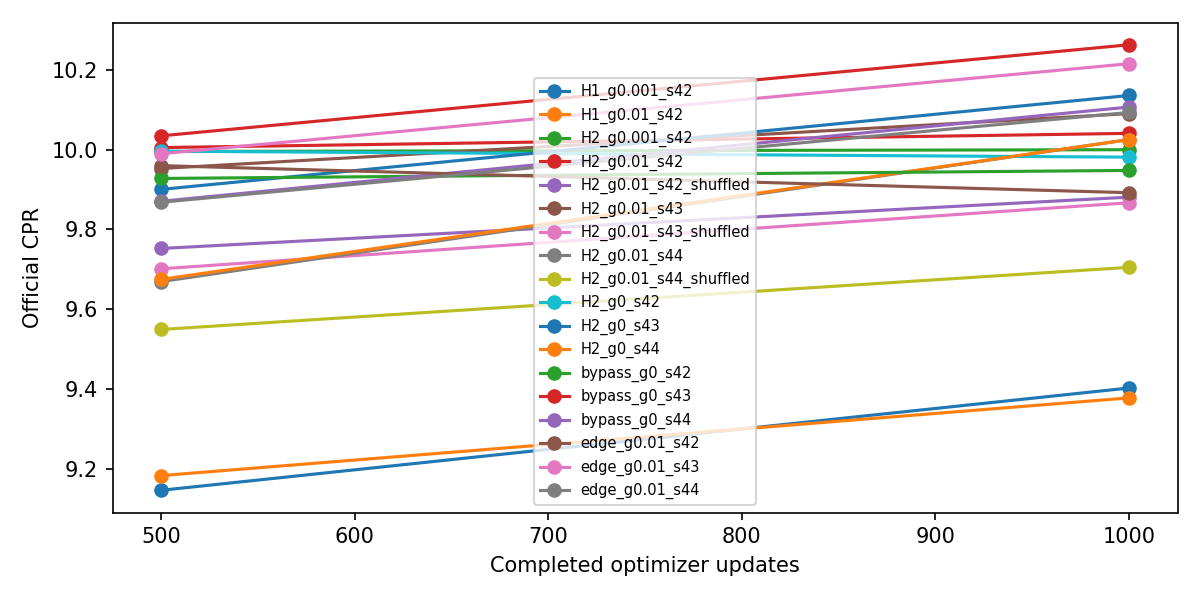

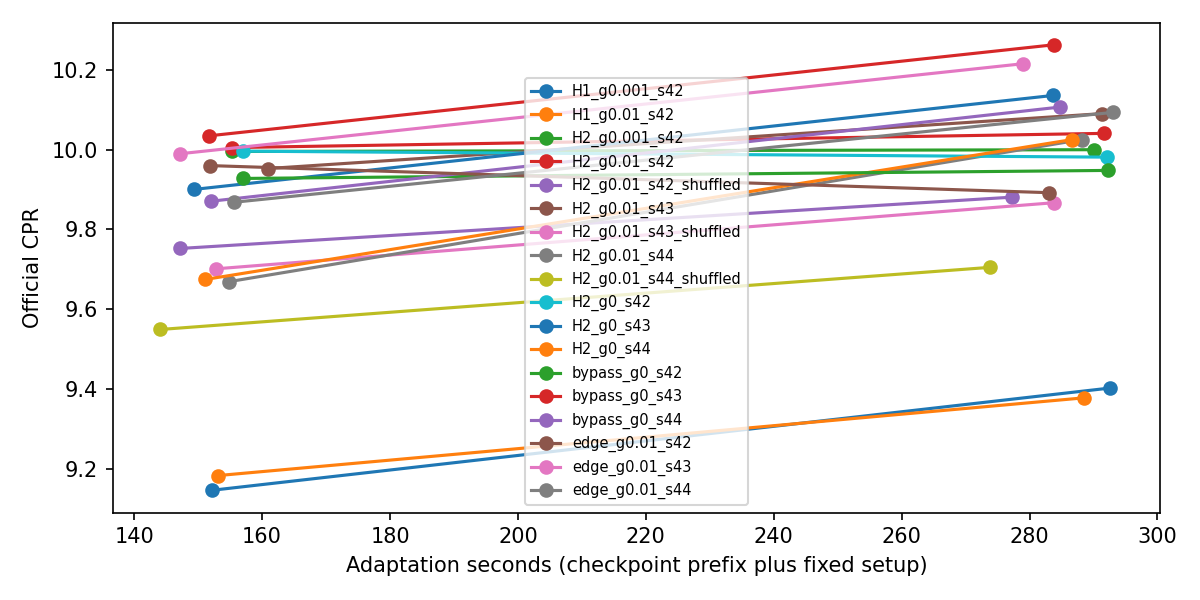

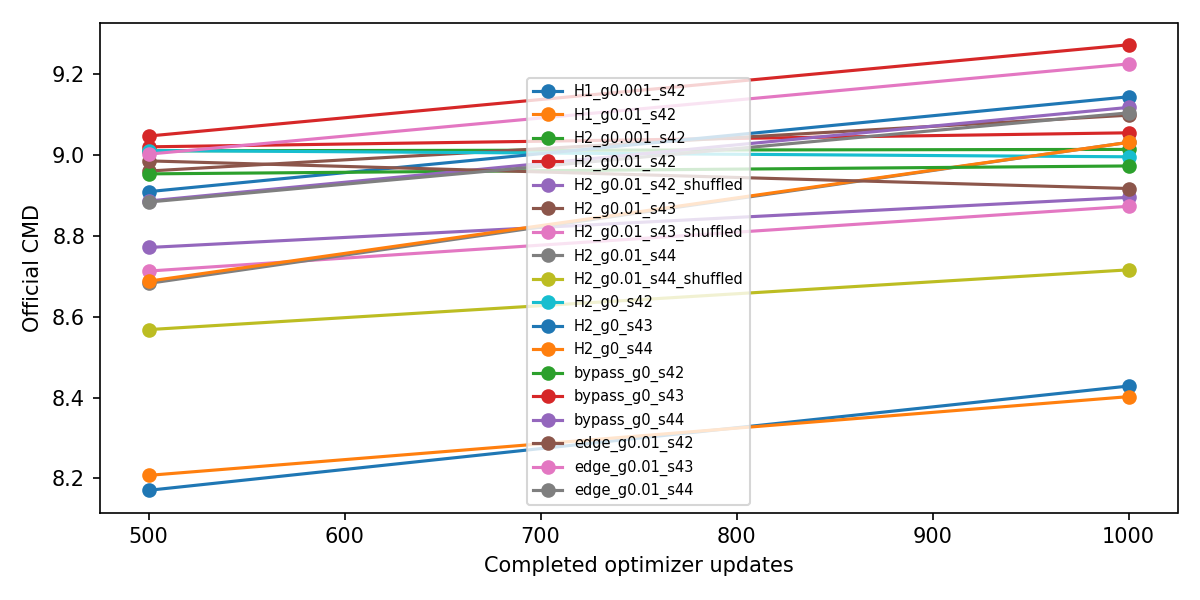

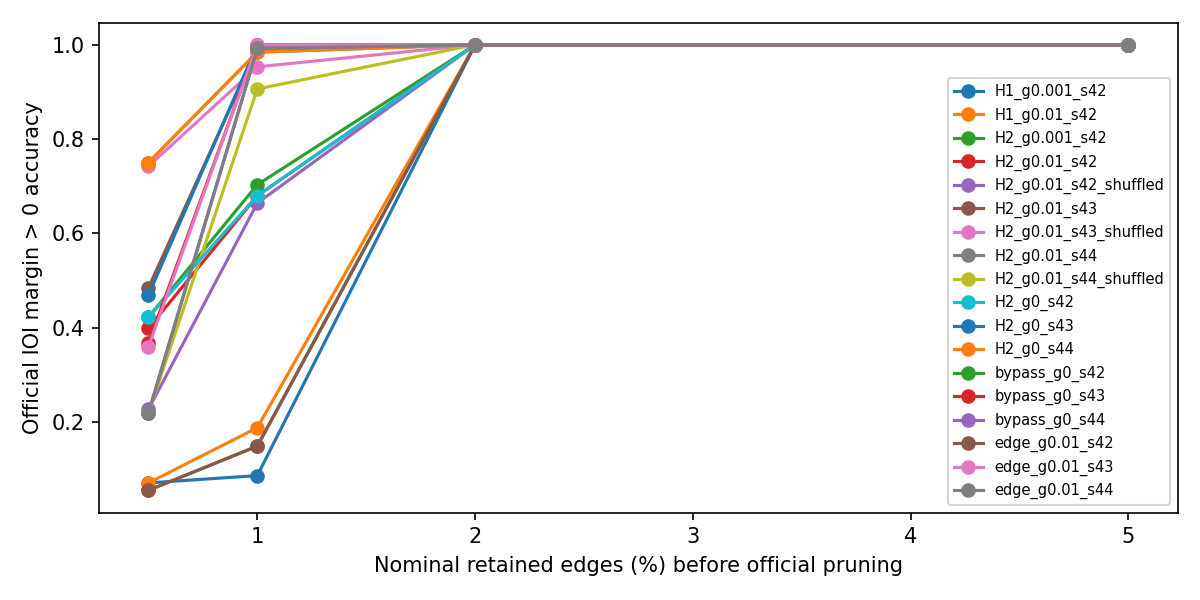

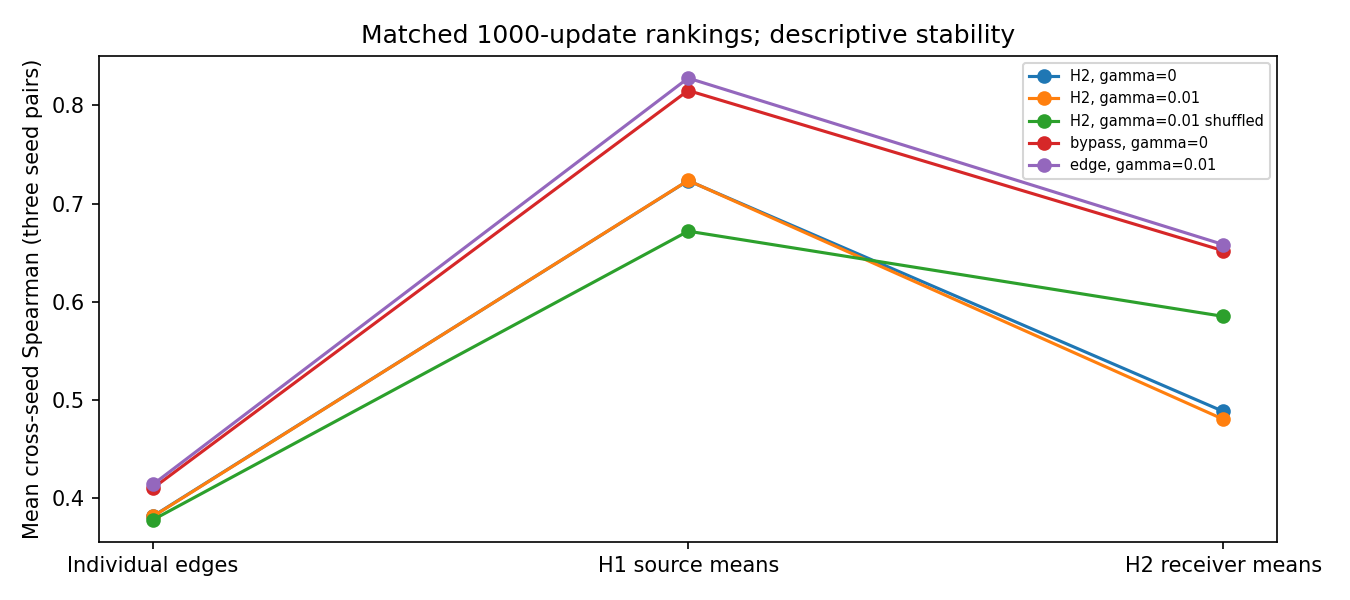

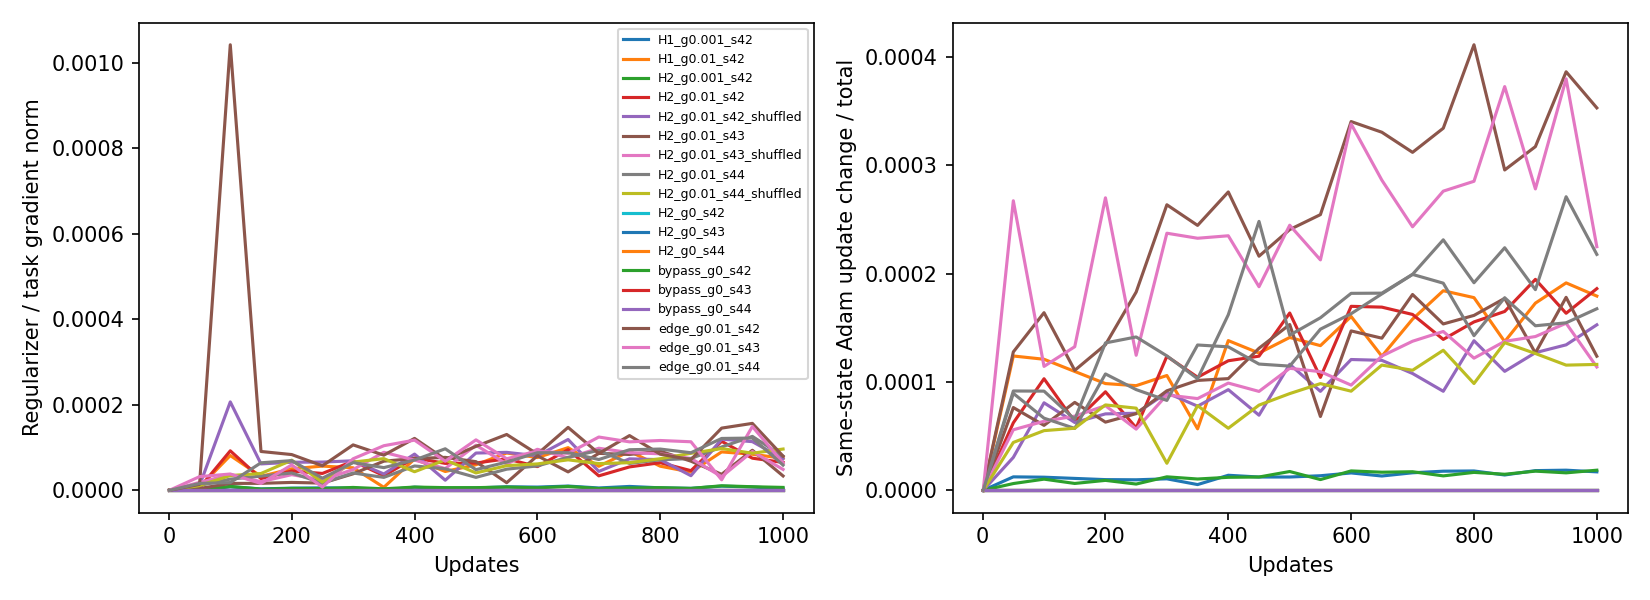

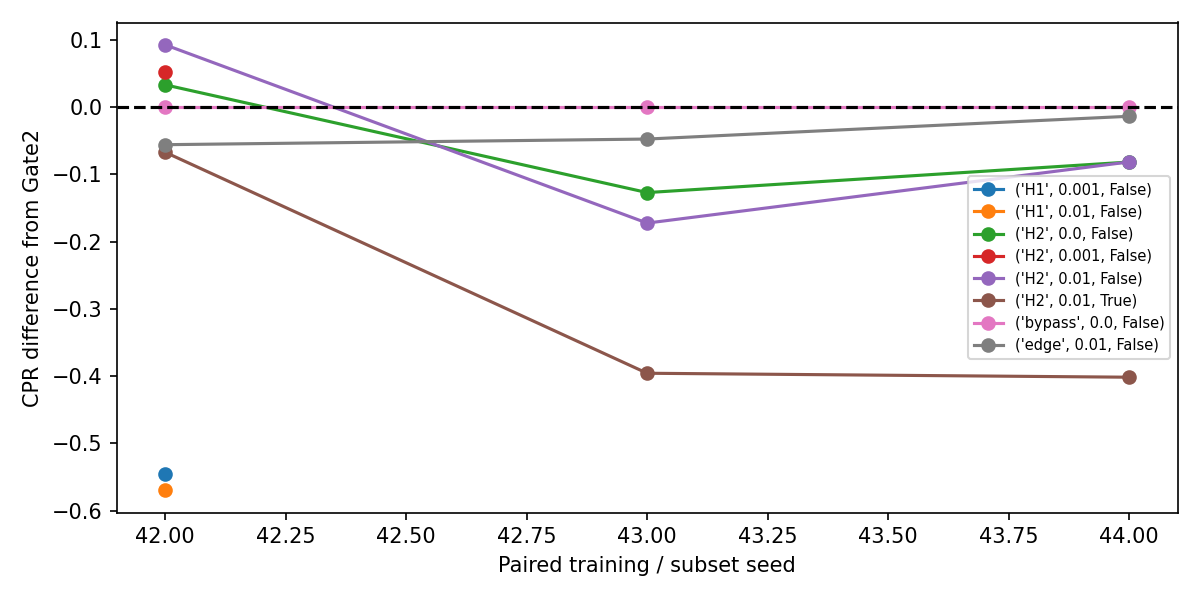

# Gate 5C: Regularized hierarchical MAttr

## Executed outcome

Both source (H1) and receiver (H2) hierarchies were tested at gamma 0.001 and 0.01. H2/gamma 0.01 passed the exploratory seed-42 screen, but failed the paired three-seed gate at 1,000 updates: mean official CPR was **10.051874 versus 10.105523** for standard MAttr (mean paired relative change **-0.517%**, positive in only **1/3** seeds). Mean CMD fell from **9.121839 to 9.062261**. Mean accuracy log-AUC rose by **0.067303**; compact positive-margin accuracy rose by **33.07 percentage points at 0.5%** retained edges and **17.19 points at 1%**, with no mean change at 2% or 5%. These accuracy gains do not meet the primary CPR objective.

The selected method exceeded shuffled grouping by 2.393% mean paired CPR, but exceeded the gamma-zero hierarchy by only 0.050% and trailed ordinary edge regularization by 0.131%. Thus the required structural-control comparisons failed. The prescribed penalty contributed very little to updates; the results do not establish a benefit from regularization or disprove all possible hierarchy designs. No significance is claimed from three paired seeds.

All correctness checks, the training-only scale probe, smoke/resume checks, four exploratory variants, three selected-hierarchy seeds, three unchanged-baseline replays, and nine control runs completed. There were **18,120 optimizer updates** including smoke checks. Training-region wall time was **82.59 minutes**; official evaluation took **17.10 minutes**; total child-process wall time including initialization and rejected variants was **108.57 minutes**. These synchronized wall times are not GPU utilization measurements. Peak CUDA allocation was **3,912.79 MiB (3.82 GiB)**. The selected method had **1.22% mean adaptation overhead**.

**Phase D was not authorized and did not run.** Keep standard MAttr as the CPR reference. Treat the compact-accuracy tradeoff as a descriptive finding on the reused 128-prompt development cohort; no full-data follow-up, leaderboard submission, or further algorithm was run.

## Actual decision

{
  "B": {
    "selected": {
      "family": "H2",
      "gamma": 0.01
    },
    "results": [
      {
        "family": "H1",
        "gamma": 0.001,
        "relative_CPR_gain": -0.05479240515818562,
        "passed": false,
        "checks": {
          "CPR": false,
          "accuracy_auc": true,
          "CMD": true,
          "adaptation_compute": true,
          "memory": true,
          "compact_0.005": true,
          "compact_0.01": false,
          "compact_0.02": true,
          "compact_0.05": true
        }
      },
      {
        "family": "H1",
        "gamma": 0.01,
        "relative_CPR_gain": -0.05727937608382472,
        "passed": false,
        "checks": {
          "CPR": false,
          "accuracy_auc": true,
          "CMD": true,
          "adaptation_compute": true,
          "memory": true,
          "compact_0.005": true,
          "compact_0.01": true,
          "compact_0.02": true,
          "compact_0.05": true
        }
      },
      {
        "family": "H2",
        "gamma": 0.001,
        "relative_CPR_gain": 0.005215436581468502,
        "passed": true,
        "checks": {
          "CPR": true,
          "accuracy_auc": true,
          "CMD": true,
          "adaptation_compute": true,
          "memory": true,
          "compact_0.005": true,
          "compact_0.01": true,
          "compact_0.02": true,
          "compact_0.05": true
        }
      },
      {
        "family": "H2",
        "gamma": 0.01,
        "relative_CPR_gain": 0.009330463477732476,
        "passed": true,
        "checks": {
          "CPR": true,
          "accuracy_auc": true,
          "CMD": true,
          "adaptation_compute": true,
          "memory": true,
          "compact_0.005": true,
          "compact_0.01": true,
          "compact_0.02": true,
          "compact_0.05": true
        }
      }
    ],
    "exploratory_seed": 42,
    "no_extra_gamma": true
  },
  "C": {
    "winner": null,
    "primary": {
      "passed": false,
      "checks": {
        "CPR": false,
        "accuracy_auc": true,
        "CMD": true,
        "adaptation_compute": true,
        "memory": true,
        "positive_seeds": false,
        "compact_0.005": true,
        "compact_0.01": true,
        "compact_0.02": true,
        "compact_0.05": true
      }
    },
    "structural_controls": {
      "H2_gamma0_shuffledFalse": {
        "passed": false,
        "checks": {
          "CPR_advantage": false,
          "positive_seeds": true,
          "accuracy_auc": true,
          "compact_0.005": true,
          "compact_0.01": true,
          "compact_0.02": true,
          "compact_0.05": true
        },
        "mean_relative_CPR_advantage": 0.0005017153900101675,
        "per_seed_relative_CPR_advantage": [
          0.005964324413581634,
          -0.0044758560029777295,
          1.667775942659766e-05
        ]
      },
      "H2_gamma0.01_shuffledTrue": {
        "passed": true,
        "checks": {
          "CPR_advantage": true,
          "positive_seeds": true,
          "accuracy_auc": true,
          "compact_0.005": true,
          "compact_0.01": true,
          "compact_0.02": true,
          "compact_0.05": true
        },
        "mean_relative_CPR_advantage": 0.02393356895954087,
        "per_seed_relative_CPR_advantage": [
          0.0161709192083479,
          0.022635936817879676,
          0.032993850852395035
        ]
      },
      "edge_gamma0.01_shuffledFalse": {
        "passed": false,
        "checks": {
          "CPR_advantage": false,
          "positive_seeds": false,
          "accuracy_auc": true,
          "compact_0.005": true,
          "compact_0.01": true,
          "compact_0.02": true,
          "compact_0.05": true
        },
        "mean_relative_CPR_advantage": -0.0013122208812638148,
        "per_seed_relative_CPR_advantage": [
          0.015023159570990652,
          -0.012234015062316694,
          -0.006725807152465402
        ]
      }
    },
    "passed": false,
    "step": 1000,
    "claim": "structural hierarchy only if primary AND all3 controls pass"
  },
  "D": null
}

## Hypothesis and mathematical objective

Shared component scores may stabilize edge importance without eliminating edge-specific deviations. Effective scores are h[g(e)] + r[e] - group_mean(r)[g(e)]. Every original32,491 edge remains eligible and trainable through this full-score-space parameterization. Zero h/r initialization; loss is official negative one-example IOI logit difference plus gamma * scale * mean(centered_residual^2). The component vector is unpenalized. A deterministic padded indexed reduction and its symmetric projection backward avoid scatter-atomic reduction ordering. No per-edge Python training loop, new top-k mask, edge restriction, model fine-tuning, expander or interaction training.

The official optimizer, uniform CPU Torch k RNG, Python example draws, temperature.5, Adam lr.05/eps1e-8/betas(.9,.999), iso live patching, float32 and MIB evaluator stay pinned. One packed Adam parameter holds h and r; this is mathematically the same elementwise Adam rule on both vectors. Model parameters never enter Adam, and their complete before/after SHA hashes must match. Official model-weight gradient flags/accumulation are preserved for exact baseline pairing; producing those gradients is not a weight update. Inference is no-grad.

## Prior research and mappings

Complete Gate1/2/3/4/5A/5B reports were read and hashed. Gate1 CPR10.588012 is a full-data/full-validation reference; matched N128 Gate2 checkpoints remain the primary comparator. Gate5B's stable components explain little edge-specific variance, so all residual directions remain available. H1 groups by official source component (including explicit input); H2 separates every head Q/K/V receiver, each MLP receiver and logits. Canonical ordering is unchanged. Shuffled controls use fixed seed5701 and preserve exact group-size distributions.

| hierarchy | count | min | max | sum |
| --- | --- | --- | --- | --- |
| H1 | 157 | 1 | 445 | 32491 |
| H2 | 445 | 1 | 157 | 32491 |

## Training-only scale inspection and correctness

{
  "scale": 1.0,
  "replaced": false,
  "negligible": false,
  "dominant": false,
  "rule": {
    "negligible": "both hierarchy high-gamma median gradient ratios<1e-4 AND median loss ratios<1e-6",
    "dominant": "both hierarchy low-gamma median gradient ratios>1 AND median loss ratios>.5",
    "replacement": "if either extreme condition holds, one common scale=.01/geometric_mean(high-gamma median gradient ratios); target1% regularizer/task gradient ratio for gamma.01. Otherwise scale1. No development-metric choice; gammas stay decade-separated.",
    "initial_gammas": [
      0.001,
      0.01
    ]
  },
  "training_only_medians": [
    {
      "family": "H1",
      "gamma": 0.001,
      "gradient_ratio": 7.17911042506116e-06,
      "loss_ratio": 0.00036785218981085,
      "mattr_abs_loss": 3.127256393432617,
      "penalty": 0.001149853458628
    },
    {
      "family": "H1",
      "gamma": 0.01,
      "gradient_ratio": 7.179109928737883e-05,
      "loss_ratio": 0.00367852137424045,
      "mattr_abs_loss": 3.127256393432617,
      "penalty": 0.0114985331892967
    },
    {
      "family": "H2",
      "gamma": 0.001,
      "gradient_ratio": 6.529254068218605e-06,
      "loss_ratio": 0.0003626527759479,
      "mattr_abs_loss": 3.127256393432617,
      "penalty": 0.0011336008319631
    },
    {
      "family": "H2",
      "gamma": 0.01,
      "gradient_ratio": 6.529253608736541e-05,
      "loss_ratio": 0.00362652761396015,
      "mattr_abs_loss": 3.127256393432617,
      "penalty": 0.0113360080868005
    }
  ],
  "probe_sha256": "9245f710b95cff1d22cf9d7d9ce391f7de68c20d5964dda2ff3d76037e2a5587"
}

The probe uses saved500-step baseline scores, four training prompts, and five fixed k values, with20 model-gradient probes and zero optimizer updates. No development metric selects the scale. Original gamma values .001/.01 are retained unless both are numerically negligible or dominant under the previously frozen training-only rule. All pilot work is charged. CPU/GPU tests cover disjoint mappings, singleton groups, zero means, full score-space rank, finite differences, official soft-mask mass/order, exact checkpoint/Adam/RNG/group identity, deterministic export and a dedicated original-parameter bypass. Gamma-zero hierarchy is NOT claimed identical to ordinary MAttr. Real30-update smoke additionally verifies patching, exact resume and unchanged GPT2 weights.

Protocol SHA-256 `3b85dbcc9a01c8e8892795bc3aa622895d4084885f239c6c351e9b8b4d36692e`; source, cohort, dependency, group mapping and historical criteria hashes are frozen before CPR screening. The preflight/probe protocol is separate and contains no outcome-driven hyperparameter replacement. Historical Gate3/4 stopping criteria are unchanged.

## Official held-out development results

| family | gamma | shuffled | seeds | cpr | CPR_gain | CMD_change | accuracy_log_AUC_change | time_ratio |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| H1 | 0.0010 | False | 1 | 9.4026 | -0.0548 | -0.5449 | -0.0045 | 1.0014 |
| H1 | 0.0100 | False | 1 | 9.3779 | -0.0573 | -0.5711 | 0.0067 | 0.9870 |
| H2 | 0.0000 | False | 3 | 10.0471 | -0.0057 | -0.0642 | 0.0636 | 1.0018 |
| H2 | 0.0010 | False | 1 | 9.9996 | 0.0052 | 0.0410 | 0.1012 | 0.9927 |
| H2 | 0.0100 | False | 3 | 10.0519 | -0.0052 | -0.0596 | 0.0673 | 1.0122 |
| H2 | 0.0100 | True | 3 | 9.8174 | -0.0283 | -0.2933 | 0.0350 | 0.9701 |
| bypass | 0.0000 | False | 3 | 10.1055 | 0.0000 | 0.0000 | 0.0000 | 1.0000 |
| edge | 0.0100 | False | 3 | 10.0666 | -0.0039 | -0.0389 | -0.0003 | 0.9935 |

| job | seed | step | cpr | baseline_cpr | relative_cpr_gain | cmd_delta | accuracy_auc_delta | time_ratio | accuracy_delta_0.005 | accuracy_delta_0.01 | accuracy_delta_0.02 | accuracy_delta_0.05 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| H1_g0.001_s42 | 42 | 1000 | 9.4026 | 9.9477 | -0.0548 | -0.5449 | -0.0045 | 1.0014 | 0.0156 | -0.0625 | 0.0000 | 0.0000 |
| H1_g0.001_s42 | 42 | 500 | 9.1463 | 9.9275 | -0.0787 | -0.7834 | 0.0103 | 0.9691 | 0.0156 | 0.0938 | -0.0078 | 0.0000 |
| H1_g0.01_s42 | 42 | 1000 | 9.3779 | 9.9477 | -0.0573 | -0.5711 | 0.0067 | 0.9870 | 0.0156 | 0.0391 | 0.0000 | 0.0000 |
| H1_g0.01_s42 | 42 | 500 | 9.1832 | 9.9275 | -0.0750 | -0.7464 | 0.0104 | 0.9749 | 0.0156 | 0.0859 | 0.0000 | 0.0000 |
| H2_g0.001_s42 | 42 | 1000 | 9.9996 | 9.9477 | 0.0052 | 0.0410 | 0.1012 | 0.9927 | 0.3672 | 0.5547 | 0.0000 | 0.0000 |
| H2_g0.001_s42 | 42 | 500 | 9.9951 | 9.9275 | 0.0068 | 0.0571 | 0.0889 | 0.9891 | 0.2109 | 0.6406 | 0.0000 | 0.0000 |
| H2_g0.01_s42 | 42 | 1000 | 10.0405 | 9.9477 | 0.0093 | 0.0821 | 0.1034 | 0.9979 | 0.3438 | 0.5312 | 0.0000 | 0.0000 |
| H2_g0.01_s42 | 42 | 500 | 10.0048 | 9.9275 | 0.0078 | 0.0669 | 0.0843 | 0.9896 | 0.1719 | 0.6406 | 0.0000 | 0.0000 |
| H2_g0.01_s42_shuffled | 42 | 1000 | 9.8807 | 9.9477 | -0.0067 | -0.0777 | 0.0718 | 0.9489 | 0.1719 | 0.5156 | 0.0000 | 0.0000 |
| H2_g0.01_s42_shuffled | 42 | 500 | 9.7521 | 9.9275 | -0.0177 | -0.1822 | 0.0434 | 0.9375 | 0.0156 | 0.4141 | 0.0000 | 0.0000 |
| H2_g0.01_s43 | 43 | 1000 | 10.0901 | 10.2624 | -0.0168 | -0.1743 | 0.0183 | 1.0267 | 0.1172 | -0.0078 | 0.0000 | 0.0000 |
| H2_g0.01_s43 | 43 | 500 | 9.9525 | 10.0343 | -0.0082 | -0.0866 | 0.0662 | 1.0612 | 0.5547 | 0.0156 | 0.0000 | 0.0000 |
| H2_g0.01_s43_shuffled | 43 | 1000 | 9.8667 | 10.2624 | -0.0386 | -0.3999 | 0.0399 | 0.9999 | 0.3750 | -0.0469 | 0.0000 | 0.0000 |
| H2_g0.01_s43_shuffled | 43 | 500 | 9.7012 | 10.0343 | -0.0332 | -0.3343 | 0.0224 | 1.0076 | 0.2188 | -0.0938 | 0.0000 | 0.0000 |
| H2_g0.01_s44 | 44 | 1000 | 10.0251 | 10.1065 | -0.0081 | -0.0865 | 0.0802 | 1.0119 | 0.5312 | -0.0078 | 0.0000 | 0.0000 |
| H2_g0.01_s44 | 44 | 500 | 9.6691 | 9.8704 | -0.0204 | -0.2040 | 0.0249 | 1.0194 | 0.1328 | 0.0938 | 0.0000 | 0.0000 |
| H2_g0.01_s44_shuffled | 44 | 1000 | 9.7049 | 10.1065 | -0.0397 | -0.4022 | -0.0068 | 0.9614 | 0.0000 | -0.0859 | 0.0000 | 0.0000 |
| H2_g0.01_s44_shuffled | 44 | 500 | 9.5492 | 9.8704 | -0.0325 | -0.3184 | -0.0054 | 0.9482 | 0.0078 | -0.0625 | 0.0000 | 0.0000 |
| H2_g0_s42 | 42 | 1000 | 9.9810 | 9.9477 | 0.0033 | 0.0227 | 0.0961 | 0.9996 | 0.3672 | 0.5312 | 0.0000 | 0.0000 |
| H2_g0_s42 | 42 | 500 | 9.9959 | 9.9275 | 0.0069 | 0.0578 | 0.0889 | 1.0005 | 0.2109 | 0.6406 | 0.0000 | 0.0000 |
| H2_g0_s43 | 43 | 1000 | 10.1354 | 10.2624 | -0.0124 | -0.1287 | 0.0146 | 0.9994 | 0.1016 | 0.0000 | 0.0000 | 0.0000 |
| H2_g0_s43 | 43 | 500 | 9.9001 | 10.0343 | -0.0134 | -0.1377 | 0.0565 | 0.9848 | 0.4375 | 0.0547 | 0.0000 | 0.0000 |
| H2_g0_s44 | 44 | 1000 | 10.0249 | 10.1065 | -0.0081 | -0.0866 | 0.0802 | 1.0064 | 0.5312 | -0.0078 | 0.0000 | 0.0000 |
| H2_g0_s44 | 44 | 500 | 9.6746 | 9.8704 | -0.0198 | -0.1985 | 0.0249 | 0.9947 | 0.1328 | 0.0938 | 0.0000 | 0.0000 |
| bypass_g0_s42 | 42 | 1000 | 9.9477 | 9.9477 | 0.0000 | 0.0000 | 0.0000 | 1.0000 | 0.0000 | 0.0000 | 0.0000 | 0.0000 |
| bypass_g0_s42 | 42 | 500 | 9.9275 | 9.9275 | 0.0000 | 0.0000 | 0.0000 | 1.0000 | 0.0000 | 0.0000 | 0.0000 | 0.0000 |
| bypass_g0_s43 | 43 | 1000 | 10.2624 | 10.2624 | 0.0000 | 0.0000 | 0.0000 | 1.0000 | 0.0000 | 0.0000 | 0.0000 | 0.0000 |
| bypass_g0_s43 | 43 | 500 | 10.0343 | 10.0343 | 0.0000 | 0.0000 | 0.0000 | 1.0000 | 0.0000 | 0.0000 | 0.0000 | 0.0000 |
| bypass_g0_s44 | 44 | 1000 | 10.1065 | 10.1065 | 0.0000 | 0.0000 | 0.0000 | 1.0000 | 0.0000 | 0.0000 | 0.0000 | 0.0000 |
| bypass_g0_s44 | 44 | 500 | 9.8704 | 9.8704 | 0.0000 | 0.0000 | 0.0000 | 1.0000 | 0.0000 | 0.0000 | 0.0000 | 0.0000 |
| edge_g0.01_s42 | 42 | 1000 | 9.8919 | 9.9477 | -0.0056 | -0.0558 | 0.0000 | 0.9687 | 0.0000 | 0.0000 | 0.0000 | 0.0000 |
| edge_g0.01_s42 | 42 | 500 | 9.9598 | 9.9275 | 0.0032 | 0.0322 | -0.0008 | 0.9675 | 0.0000 | -0.0078 | 0.0000 | 0.0000 |
| edge_g0.01_s43 | 43 | 1000 | 10.2150 | 10.2624 | -0.0046 | -0.0474 | -0.0009 | 0.9831 | -0.0078 | 0.0000 | 0.0000 | 0.0000 |
| edge_g0.01_s43 | 43 | 500 | 9.9895 | 10.0343 | -0.0045 | -0.0448 | 0.0000 | 0.9704 | 0.0000 | 0.0000 | 0.0000 | 0.0000 |
| edge_g0.01_s44 | 44 | 1000 | 10.0930 | 10.1065 | -0.0013 | -0.0135 | 0.0000 | 1.0288 | 0.0000 | 0.0000 | 0.0000 | 0.0000 |
| edge_g0.01_s44 | 44 | 500 | 9.8679 | 9.8704 | -0.0002 | -0.0026 | 0.0027 | 1.0242 | 0.0234 | 0.0000 | 0.0000 | 0.0000 |

Complete official faithfulness/accuracy curves and pruned counts are retained. Compact fractions are nominal ranking cutoffs followed by official connectivity pruning. Official accuracy here is positive IOI margin, not vocabulary top1. CPR rewards normalized logit amplification and is unbounded; higher CPR accompanied by higher CMD is not improved full-model fidelity. No homemade CPR/CMD is used.

## Controls, stopping and structural analysis

Seed42 screening requires>=.5% CPR gain, all compact and accuracy-log-AUC drops<=.02, CMD increase<=positive CPR gain+.05, <=10% adaptation/memory overhead. At most one candidate advances by CPR, compact accuracy, lower gamma and hierarchy tie breaks. PhaseC requires mean paired CPR>=2%, at least2 positive seeds, the same mean accuracy/CMD safeguards, <=10% adaptation overhead, and real hierarchy beating gamma-zero, size-matched shuffle and generic edge L2 controls by>=.5% mean CPR and>=2 seeds without accuracy regressions. Control failure is parameterization/regularization evidence at most, never a structural claim. Only a full PhaseC pass authorizes5000-step continuation with all necessary controls. Failed screening means no extra gamma values, no additional seeds or confirmation. Modified5000-step performance remains untested when stopped.

Learned h, centered residuals, their variances, effective score vectors, true-component score means and top-edge counts are saved. ranking_stability.csv reports paired edge/component Spearman and official pruned-edge Jaccard only when seeds are actually run. A one-seed pilot cannot establish ranking transferability. structural_component_statistics.csv distinguishes attention, MLP and schema categories with size-normalized variances. Smoother/stabler scores alone do not establish causal fidelity. Existing paired seeds vary both discovery subsets and optimizer RNG. No statistical significance claim from three seeds or the repeatedly reused128-prompt development cohort.

## Computation and limitations

| job | adaptation_seconds | training_seconds | evaluation_seconds | stage_seconds | peak_allocated_mib | cpu_rss_mib | forward_batches | example_forwards | backward_calls | optimizer_updates |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| H1_g0.001_s42 | 291.6487 | 280.1827 | 55.7833 | 344.2125 | 3912.7808 | 3033.4453 | 1464 | 7272 | 1000 | 1000 |
| H1_g0.01_s42 | 287.4577 | 276.4392 | 57.5470 | 341.8781 | 3912.7808 | 3064.0586 | 1464 | 7272 | 1000 | 1000 |
| H2_g0.001_s42 | 289.1354 | 278.9097 | 55.9142 | 342.1566 | 3912.7856 | 3056.8945 | 1464 | 7272 | 1000 | 1000 |
| H2_g0.01_s42 | 290.6457 | 280.2339 | 55.9027 | 343.6338 | 3912.7856 | 3059.1094 | 1464 | 7272 | 1000 | 1000 |
| H2_g0.01_s42_shuffled | 276.3035 | 266.2859 | 54.1788 | 327.4741 | 3912.7856 | 3073.0664 | 1464 | 7272 | 1000 | 1000 |
| H2_g0.01_s43 | 290.4066 | 279.2434 | 56.1382 | 343.6209 | 3907.9312 | 2975.3164 | 1464 | 7272 | 1000 | 1000 |
| H2_g0.01_s43_shuffled | 282.7957 | 271.3230 | 54.6707 | 334.5541 | 3907.9312 | 2965.5469 | 1464 | 7272 | 1000 | 1000 |
| H2_g0.01_s44 | 287.2196 | 274.3623 | 57.0656 | 341.2144 | 3901.6265 | 3026.1172 | 1464 | 7272 | 1000 | 1000 |
| H2_g0.01_s44_shuffled | 272.8374 | 263.2568 | 54.2550 | 324.2485 | 3901.6265 | 3001.4258 | 1464 | 7272 | 1000 | 1000 |
| H2_g0_s42 | 291.1423 | 279.6818 | 55.8449 | 344.0697 | 3912.7856 | 3070.5586 | 1464 | 7272 | 1000 | 1000 |
| H2_g0_s43 | 282.6456 | 271.7123 | 54.5513 | 334.1895 | 3907.9312 | 3069.3516 | 1464 | 7272 | 1000 | 1000 |
| H2_g0_s44 | 285.6526 | 275.2327 | 54.2732 | 337.0181 | 3901.6265 | 2991.6289 | 1464 | 7272 | 1000 | 1000 |
| bypass_g0_s42 | 291.2500 | 281.3461 | 58.1017 | 346.1063 | 3911.3560 | 2855.2031 | 1464 | 7272 | 1000 | 1000 |
| bypass_g0_s43 | 282.8213 | 272.7940 | 55.8065 | 335.5594 | 3906.5015 | 2855.4570 | 1464 | 7272 | 1000 | 1000 |
| bypass_g0_s44 | 283.8199 | 272.4676 | 56.1152 | 336.6194 | 3900.1968 | 2931.6211 | 1464 | 7272 | 1000 | 1000 |
| edge_g0.01_s42 | 282.0986 | 272.6981 | 53.9922 | 333.2589 | 3911.3560 | 2970.1836 | 1464 | 7272 | 1000 | 1000 |
| edge_g0.01_s43 | 278.0295 | 268.3991 | 53.9683 | 328.9982 | 3906.5015 | 2957.9805 | 1464 | 7272 | 1000 | 1000 |
| edge_g0.01_s44 | 292.0066 | 281.7126 | 54.2731 | 343.2532 | 3900.1968 | 2868.3828 | 1464 | 7272 | 1000 | 1000 |
| pilot | 26.8739 | 0.0000 | 0.0000 | 24.8601 | 923.8706 | 2961.4453 | 36 | 36 | 20 | 0 |
| phaseA_smoke | 55.7393 | 8.8501 | 27.9114 | 81.1368 | 3095.3901 | 2983.2656 | 325 | 3229 | 120 | 120 |

Instrumented stages total **103.134min**; optimizer updates **18,120**, backward calls **18,140**, actual root forwards **26,713**, example-forwards **134,161**. All rejected variants, probes, bypass/reference checks, exact-resume checks and restarts are charged. Launch timers additionally include interpreter/source checks. Group construction is charged to deployable adaptation, CPU report/tests/audits are additional research work. The score-operation microbenchmark reports transform/MSE/backward overhead separately and does not isolate regularization time within the full model backward. Gradient diagnostics use analytic penalty gradients and a read-only same-state Adam counterfactual, not extra model backpropagation or a changed optimizer. Prefix500/2500 compute uses measured checkpoint training plus fixed setup; those are not separate launches. Cold restarts rebuild donor caches and are charged.

Peak allocated CUDA memory **3912.8MiB** is PyTorch allocator usage, not total physical VRAM occupancy. Sampled CPU RSS is saved. Exact evaluation cache hits add no forwards. No setting changes silently after OOM. Raw vectors/checkpoints and prompt data remain local; small summaries/configurations/logs/figures are versioned. Full-data Gate1 follow-up, fresh-cohort generalization, deferred ranking refinement, OptionA, further algorithms and leaderboard submission are not run automatically.

## Recommendation

Apply the frozen decisions above. A negative screen supports retaining ordinary MAttr and does not disprove hierarchy under all possible schedules. A positive development result still needs independent validation and a separately authorized full-data comparison. Stop at Gate5C.








## Effective-score decomposition and measured penalty contribution

This supplementary analysis is descriptive and does not change the frozen selection or advancement criteria. Group means are expanded back to edges before computing the component fraction of effective-score variance, so unequal group sizes are accounted for. Centered residuals are orthogonal to group-constant scores up to floating-point error. Original packed, raw residual, centered residual and exact exported effective vectors are saved locally at each evaluated checkpoint.

| job | family | gamma | shuffled | seed | step | weighted_component_variance | centered_residual_variance | effective_variance | component_variance_fraction | residual_variance_fraction | variance_additivity_error | between_component_variance_unweighted |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| H1_g0.001_s42 | H1 | 0.0010 | False | 42 | 1000 | 0.1783 | 2.3003 | 2.4786 | 0.0720 | 0.9280 | -0.0000 | 0.9928 |
| H1_g0.001_s42 | H1 | 0.0010 | False | 42 | 500 | 0.1579 | 1.4557 | 1.6136 | 0.0979 | 0.9021 | -0.0000 | 0.7693 |
| H1_g0.01_s42 | H1 | 0.0100 | False | 42 | 1000 | 0.1831 | 2.2868 | 2.4700 | 0.0741 | 0.9259 | 0.0000 | 0.9955 |
| H1_g0.01_s42 | H1 | 0.0100 | False | 42 | 500 | 0.1496 | 1.4689 | 1.6185 | 0.0924 | 0.9076 | -0.0000 | 0.7705 |
| H2_g0.001_s42 | H2 | 0.0010 | False | 42 | 1000 | 0.2137 | 2.0729 | 2.2866 | 0.0935 | 0.9065 | -0.0000 | 1.0211 |
| H2_g0.001_s42 | H2 | 0.0010 | False | 42 | 500 | 0.1704 | 1.2650 | 1.4354 | 0.1187 | 0.8813 | -0.0000 | 0.6513 |
| H2_g0.01_s42 | H2 | 0.0100 | False | 42 | 1000 | 0.1978 | 2.0369 | 2.2347 | 0.0885 | 0.9115 | -0.0000 | 1.0051 |
| H2_g0.01_s42 | H2 | 0.0100 | False | 42 | 500 | 0.1701 | 1.2612 | 1.4313 | 0.1188 | 0.8812 | 0.0000 | 0.6500 |
| H2_g0.01_s42_shuffled | H2 | 0.0100 | True | 42 | 1000 | 0.1738 | 2.1950 | 2.3687 | 0.0734 | 0.9266 | 0.0000 | 0.3735 |
| H2_g0.01_s42_shuffled | H2 | 0.0100 | True | 42 | 500 | 0.1586 | 1.4082 | 1.5668 | 0.1012 | 0.8988 | -0.0000 | 0.3123 |
| H2_g0.01_s43 | H2 | 0.0100 | False | 43 | 1000 | 0.2513 | 2.2049 | 2.4562 | 0.1023 | 0.8977 | 0.0000 | 1.3211 |
| H2_g0.01_s43 | H2 | 0.0100 | False | 43 | 500 | 0.1644 | 1.2506 | 1.4150 | 0.1162 | 0.8838 | 0.0000 | 0.8235 |
| H2_g0.01_s43_shuffled | H2 | 0.0100 | True | 43 | 1000 | 0.1703 | 2.4263 | 2.5967 | 0.0656 | 0.9344 | 0.0000 | 0.4356 |
| H2_g0.01_s43_shuffled | H2 | 0.0100 | True | 43 | 500 | 0.1678 | 1.4844 | 1.6522 | 0.1016 | 0.8984 | 0.0000 | 0.3017 |
| H2_g0.01_s44 | H2 | 0.0100 | False | 44 | 1000 | 0.1990 | 1.9387 | 2.1377 | 0.0931 | 0.9069 | -0.0000 | 1.0949 |
| H2_g0.01_s44 | H2 | 0.0100 | False | 44 | 500 | 0.1655 | 1.1776 | 1.3431 | 0.1232 | 0.8768 | -0.0000 | 0.7181 |
| H2_g0.01_s44_shuffled | H2 | 0.0100 | True | 44 | 1000 | 0.1621 | 2.0090 | 2.1711 | 0.0747 | 0.9253 | 0.0000 | 0.3626 |
| H2_g0.01_s44_shuffled | H2 | 0.0100 | True | 44 | 500 | 0.1780 | 1.3210 | 1.4990 | 0.1187 | 0.8813 | -0.0000 | 0.3006 |
| H2_g0_s42 | H2 | 0.0000 | False | 42 | 1000 | 0.2170 | 2.0708 | 2.2878 | 0.0948 | 0.9052 | 0.0000 | 1.0248 |
| H2_g0_s42 | H2 | 0.0000 | False | 42 | 500 | 0.1705 | 1.2654 | 1.4359 | 0.1187 | 0.8813 | 0.0000 | 0.6512 |
| H2_g0_s43 | H2 | 0.0000 | False | 43 | 1000 | 0.2372 | 2.2246 | 2.4618 | 0.0964 | 0.9036 | -0.0000 | 1.3244 |
| H2_g0_s43 | H2 | 0.0000 | False | 43 | 500 | 0.1693 | 1.2639 | 1.4331 | 0.1181 | 0.8819 | 0.0000 | 0.8373 |
| H2_g0_s44 | H2 | 0.0000 | False | 44 | 1000 | 0.1995 | 1.9461 | 2.1456 | 0.0930 | 0.9070 | 0.0000 | 1.0941 |
| H2_g0_s44 | H2 | 0.0000 | False | 44 | 500 | 0.1654 | 1.1797 | 1.3451 | 0.1230 | 0.8770 | 0.0000 | 0.7180 |
| bypass_g0_s42 | bypass | 0.0000 | False | 42 | 1000 | 0.0000 | 1.9044 | 1.9044 | 0.0000 | 1.0000 | 0.0000 | 0.0000 |
| bypass_g0_s42 | bypass | 0.0000 | False | 42 | 500 | 0.0000 | 1.1891 | 1.1891 | 0.0000 | 1.0000 | 0.0000 | 0.0000 |
| bypass_g0_s43 | bypass | 0.0000 | False | 43 | 1000 | 0.0000 | 2.0900 | 2.0900 | 0.0000 | 1.0000 | 0.0000 | 0.0000 |
| bypass_g0_s43 | bypass | 0.0000 | False | 43 | 500 | 0.0000 | 1.2155 | 1.2155 | 0.0000 | 1.0000 | 0.0000 | 0.0000 |
| bypass_g0_s44 | bypass | 0.0000 | False | 44 | 1000 | 0.0000 | 1.7365 | 1.7365 | 0.0000 | 1.0000 | 0.0000 | 0.0000 |
| bypass_g0_s44 | bypass | 0.0000 | False | 44 | 500 | 0.0000 | 1.0291 | 1.0291 | 0.0000 | 1.0000 | 0.0000 | 0.0000 |
| edge_g0.01_s42 | edge | 0.0100 | False | 42 | 1000 | 0.0000 | 1.8963 | 1.8963 | 0.0000 | 1.0000 | 0.0000 | 0.0000 |
| edge_g0.01_s42 | edge | 0.0100 | False | 42 | 500 | 0.0000 | 1.2086 | 1.2086 | 0.0000 | 1.0000 | 0.0000 | 0.0000 |
| edge_g0.01_s43 | edge | 0.0100 | False | 43 | 1000 | 0.0000 | 2.0842 | 2.0842 | 0.0000 | 1.0000 | 0.0000 | 0.0000 |
| edge_g0.01_s43 | edge | 0.0100 | False | 43 | 500 | 0.0000 | 1.2103 | 1.2103 | 0.0000 | 1.0000 | 0.0000 | 0.0000 |
| edge_g0.01_s44 | edge | 0.0100 | False | 44 | 1000 | 0.0000 | 1.7320 | 1.7320 | 0.0000 | 1.0000 | 0.0000 | 0.0000 |
| edge_g0.01_s44 | edge | 0.0100 | False | 44 | 500 | 0.0000 | 1.0275 | 1.0275 | 0.0000 | 1.0000 | 0.0000 | 0.0000 |

| job | median_abs_task_loss | median_regularization_loss | median_gradient_ratio | median_Adam_update_contribution | max_Adam_update_contribution |
| --- | --- | --- | --- | --- | --- |
| H1_g0.001_s42 | 61.3497 | 0.0015 | 0.0000 | 0.0000 | 0.0000 |
| H1_g0.01_s42 | 61.3171 | 0.0147 | 0.0001 | 0.0001 | 0.0002 |
| H2_g0.001_s42 | 75.9598 | 0.0013 | 0.0000 | 0.0000 | 0.0000 |
| H2_g0.01_s42 | 75.8964 | 0.0126 | 0.0001 | 0.0001 | 0.0002 |
| H2_g0.01_s42_shuffled | 71.3937 | 0.0141 | 0.0001 | 0.0001 | 0.0002 |
| H2_g0.01_s43 | 75.9626 | 0.0125 | 0.0000 | 0.0001 | 0.0002 |
| H2_g0.01_s43_shuffled | 75.6846 | 0.0148 | 0.0001 | 0.0001 | 0.0002 |
| H2_g0.01_s44 | 79.0753 | 0.0117 | 0.0001 | 0.0001 | 0.0002 |
| H2_g0.01_s44_shuffled | 76.6056 | 0.0132 | 0.0001 | 0.0001 | 0.0001 |
| H2_g0_s42 | 75.9626 | 0.0000 | 0.0000 | 0.0000 | 0.0000 |
| H2_g0_s43 | 77.4186 | 0.0000 | 0.0000 | 0.0000 | 0.0000 |
| H2_g0_s44 | 79.0755 | 0.0000 | 0.0000 | 0.0000 | 0.0000 |
| bypass_g0_s42 | 74.9707 | 0.0000 | 0.0000 | 0.0000 | 0.0000 |
| bypass_g0_s43 | 75.4402 | 0.0000 | 0.0000 | 0.0000 | 0.0000 |
| bypass_g0_s44 | 77.3835 | 0.0000 | 0.0000 | 0.0000 | 0.0000 |
| edge_g0.01_s42 | 75.8211 | 0.0172 | 0.0001 | 0.0003 | 0.0004 |
| edge_g0.01_s43 | 76.2010 | 0.0142 | 0.0001 | 0.0002 | 0.0004 |
| edge_g0.01_s44 | 77.3645 | 0.0127 | 0.0001 | 0.0002 | 0.0003 |

The prescribed mean-square coefficients have small aggregate gradient norms; same-state Adam contribution is a more direct diagnostic of their update effect. This does not authorize another gamma or scale sweep. Coarse score sharing can still remove edge-specific ranking information, and component stability without corresponding official accuracy/CMD evidence does not establish better causal fidelity.

## Final artifact audit

{
  "passed": true,
  "historical_files_unchanged": 9457,
  "historical_criteria_sha256": "f200fc163bfb0e70b4790bde28ed3a6748bf9051c7d574ed7e23bda69cf0dbde",
  "protocol_sha256": "3b85dbcc9a01c8e8892795bc3aa622895d4084885f239c6c351e9b8b4d36692e",
  "jobs": 20,
  "checkpoints": 183,
  "cpu_tests": 6,
  "all_original_edges": 32491,
  "groups": {
    "H1": 157,
    "H2": 445
  },
  "exact_bypass_and_resume": true,
  "weight_updates": 0,
  "effective_exports_verified": true,
  "cohort_and_row_k_streams_match": true,
  "decisions_recomputed_unchanged": true,
  "counts": {
    "forward_batches": 26713,
    "example_forwards": 134161,
    "backward_calls": 18140,
    "optimizer_updates": 18120
  },
  "total_child_launch_seconds": 6514.190938558,
  "additional_model_forwards_for_audit": 0,
  "audit_seconds": 119.074398134
}


## Accounting reconciliation

The nested pilot patching check was included in its parent timer. The descriptive stage sum duplicated 13 root forwards and 13 example-forwards; the reconciled total is **26,713 root forwards**, **134,161 example-forwards**, **18,140 backward calls**, and **18,120 optimizer updates**. The overlap of 1.525 seconds is also removed from aggregate stage time. Original stage sums remain in `compute_accounting_stage_aggregate.csv`; unique process counters match `final_validation.json`. Timed training, official evaluations, candidate comparisons, frozen decisions, and total child-process wall time are unchanged. The pilot outer-stage false flag reflects its intentional completion sentinel; its process succeeded.


In [7]:
for name in ['cpr_vs_steps', 'cpr_vs_compute', 'cmd_vs_steps', 'compact_accuracy', 'component_vs_edge_stability', 'regularization_diagnostics', 'paired_cpr_differences']:
    display(Image(filename=str(OUT / 'figures' / (name + '.png'))))
body = (OUT / 'GATE5C_HIERARCHICAL_MATTR_REPORT.md').read_text()
body = re.sub(r'^!\[.*?\]\(.*?\)\s*$', '', body, flags=re.MULTILINE)
display(Markdown(body))
